In [ ]:
# ==============================================================================
# Import
# ==============================================================================
import os
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    TimeSeriesSplit, GridSearchCV, cross_val_score,
    LeaveOneGroupOut, train_test_split
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNet, Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    mean_absolute_percentage_error
)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyRegressor
from xgboost import XGBRegressor

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

OUT_DIR = "publication_outputs"
os.makedirs(f"{OUT_DIR}/tables", exist_ok=True)
os.makedirs(f"{OUT_DIR}/figures", exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 10, 'axes.labelsize': 11, 'axes.titlesize': 12,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9,
    'savefig.dpi': 600, 'savefig.bbox': 'tight',
    'savefig.facecolor': 'white', 'figure.facecolor': 'white'
})
sns.set_style("whitegrid")

print("=" * 80)
print("MACHINE LEARNING ANALYSIS FOR COFFEE PRODUCTION FORECASTING")
print("Western Hararghe Zone, Ethiopia")
print("=" * 80)
print("[STUDY PERIOD] 2000–2015 Ethiopian Calendar (≈2008–2023 Gregorian)")
print("[TARGET] Total Coffee Production (tons)")
print("[DESIGN] Leakage-safe temporal validation")
print("[RANDOM SEED]", RANDOM_SEED)

MACHINE LEARNING ANALYSIS FOR COFFEE PRODUCTION FORECASTING
Western Hararghe Zone, Ethiopia
[STUDY PERIOD] 2000–2015 Ethiopian Calendar (≈2008–2023 Gregorian)
[TARGET] Total Coffee Production (tons)
[DESIGN] Leakage-safe temporal validation
[RANDOM SEED] 42


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ==============================================================================
# PART 1 — Data Loading + District detection + District value mapping
# ==============================================================================
DATA_PATH = '/content/drive/MyDrive/Coff_Poduction.csv'
data = pd.read_csv(DATA_PATH, encoding='latin1')

print(f"Shape: {data.shape}")
print(f"Columns: {list(data.columns)}")

# --- Detect District column ---
district_candidates = [
    'District_Name', 'District', 'district', 'DISTRICT',
    'district_name', 'Woreda', 'woreda', 'WOREDA'
]
DISTRICT_COL = None
for cand in district_candidates:
    if cand in data.columns:
        DISTRICT_COL = cand
        break
if DISTRICT_COL is None:
    for col in data.columns:
        low = col.lower()
        if 'district' in low or 'woreda' in low:
            DISTRICT_COL = col
            break

if DISTRICT_COL is None:
    raise ValueError("District column is required for audit.")

# --- Rename COLUMN to 'District' ---
if DISTRICT_COL != 'District':
    data = data.rename(columns={DISTRICT_COL: 'District'})
DISTRICT_COL = 'District'

# --- RAW district values in the CSV ---
print(f"\n[OK] District column detected: '{DISTRICT_COL}'")
print("\n[RAW district values in CSV]")
print(data['District'].value_counts().to_string())

# --- change district  names ---
DISTRICT_NAME_MAP = {
    'Boke':   'Boke',
    'D/Labu': 'Dara Labu',
    'Habro':  'Habro',
    'Mesela': 'Shanan_dhugo',
    'Tulo':   'Tulo',
}

unmapped = set(data['District'].dropna().unique()) - set(DISTRICT_NAME_MAP.keys())
if unmapped:
    print(f"\n[WARNING] Unmapped district values: {sorted(unmapped)}")

# Apply mapping — values not in the map stay unchanged
data['District'] = data['District'].map(DISTRICT_NAME_MAP)\
                                  .fillna(data['District'])

print("\n[Changed district names (after mapping)]")
print(data['District'].value_counts().to_string())

print(f"\n[OK] Unique districts ({data['District'].nunique()}): "
      f"{sorted(data['District'].dropna().unique().tolist())}")

Shape: (500, 17)
Columns: ['District_Name', 'Year', 'Area(hec)', 'pH', 'Tot. N (%)', 'Avail. P (ppm)', 'Exch. K (ppm)', 'Org. C (%)', 'Fertilizers', 'Soil Type', 'ANN_Temperature', 'Precipitation(mm/day)', 'Relative_humidity', 'ANN_ Wind Speed(m/s)', 'Solar_radiation(MJ/mÂ²/day)', 'Soil wetness', 'Yeild(tone/hect)']

[OK] District column detected: 'District'

[RAW district values in CSV]
District
Mesela    100
Tulo      100
Habro     100
D/Labu    100
Boke      100

[Changed district names (after mapping)]
District
Shanan_dhugo    100
Tulo            100
Habro           100
Dara Labu       100
Boke            100

[OK] Unique districts (5): ['Boke', 'Dara Labu', 'Habro', 'Shanan_dhugo', 'Tulo']


In [ ]:
# ==============================================================================
# PART 2 — Target + Column Renaming
# ==============================================================================
data = data.rename(columns={'Yeild(tone/hect)': 'Production_tons'})

column_renames = {
    'Area(hec)': 'Cultivated_Area_ha',
    'Tot. N (%)': 'Total_N_percent',
    'Avail. P (ppm)': 'Available_P_ppm',
    'Exch. K (ppm)': 'Exchangeable_K_ppm',
    'Org. C (%)': 'Organic_C_percent',
    'ANN_Temperature': 'Annual_Temperature_C',
    'Precipitation(mm/day)': 'Precipitation_mm_day',
    'Relative_humidity': 'Relative_Humidity_percent',
    'ANN_ Wind Speed(m/s)': 'Wind_Speed_m_s',
    'Solar_radiation(MJ/mÂ²/day)': 'Solar_Radiation_MJ_m2_day',
    'Soil wetness': 'Soil_Wetness',
    'Soil Type': 'Soil_Type',
    'Fertilizers': 'Fertilizer_Used'
}
data = data.rename(columns=column_renames)

print("[TARGET] Production_tons (total production in tons)")
print(f"  Range: {data['Production_tons'].min():.1f} – {data['Production_tons'].max():.1f}")
print(f"  Mean ± SD: {data['Production_tons'].mean():.1f} ± {data['Production_tons'].std():.1f}")

[TARGET] Production_tons (total production in tons)
  Range: 518.2 – 6509.0
  Mean ± SD: 2515.9 ± 1219.1


In [ ]:
# ==============================================================================
# CRITICAL #3 + #15 — Data-quality audit + extreme-value verification
# ==============================================================================
print("\n" + "=" * 80)
print("DATA-QUALITY AUDIT TABLE")
print("=" * 80)

quality_rows = []
for col in data.columns:
    if col in ['Year', 'District']:
        continue
    series = data[col]
    if pd.api.types.is_numeric_dtype(series):
        q1, q3 = series.quantile(0.25), series.quantile(0.75)
        iqr = q3 - q1
        n_out = ((series < q1 - 1.5*iqr) | (series > q3 + 1.5*iqr)).sum()
        quality_rows.append({
            'Variable': col, 'Type': 'numeric',
            'N': series.count(), 'Missing': series.isnull().sum(),
            'Missing_%': round(100*series.isnull().sum()/len(series), 2),
            'Min': series.min(), 'Max': series.max(),
            'Mean': round(series.mean(), 3),
            'Outlier_IQR_count': n_out
        })
    else:
        quality_rows.append({
            'Variable': col, 'Type': 'categorical',
            'N': series.count(), 'Missing': series.isnull().sum(),
            'Missing_%': round(100*series.isnull().sum()/len(series), 2),
            'Min': np.nan, 'Max': np.nan, 'Mean': np.nan,
            'Outlier_IQR_count': np.nan
        })

quality_df = pd.DataFrame(quality_rows)
quality_df.to_csv(f"{OUT_DIR}/tables/Table_S1_Data_Quality_Audit.csv", index=False)
quality_df.to_excel(f"{OUT_DIR}/tables/Table_S1_Data_Quality_Audit.xlsx", index=False)
print(quality_df.to_string())
print("\n[SAVED] Table_S1_Data_Quality_Audit")

print("\n[EXTREME VALUE VERIFICATION]")
print(f"  pH min = {data['pH'].min():.4f}  → retained")
print(f"  Total_N max = {data['Total_N_percent'].max():.3f}%  → retained")
print(f"  Annual_Temperature mean = {data['Annual_Temperature_C'].mean():.2f} °C")
print("  → All extreme values retained; median imputation only inside CV folds")


DATA-QUALITY AUDIT TABLE
                     Variable         Type    N  Missing  Missing_%          Min          Max       Mean  Outlier_IQR_count
0          Cultivated_Area_ha      numeric  500        0        0.0  4202.352207  20603.30107  11134.120                0.0
1                          pH      numeric  500        0        0.0     5.000000      6.69000      5.831                0.0
2             Total_N_percent      numeric  500        0        0.0     0.060000      0.20000      0.129                0.0
3             Available_P_ppm      numeric  500        0        0.0     7.000000     14.99000     11.154                0.0
4          Exchangeable_K_ppm      numeric  500        0        0.0    91.400000    597.00000    304.083                0.0
5           Organic_C_percent      numeric  500        0        0.0     0.510000      1.89000      1.199                0.0
6             Fertilizer_Used  categorical  500        0        0.0          NaN          NaN        NaN  

In [ ]:
# ==============================================================================
# — Observation unit / district-year counts
# ==============================================================================
print("\n" + "=" * 80)
print("OBSERVATION UNIT — AUDIT")
print("=" * 80)

if 'District' in data.columns:
    # District × Year counts — mapped district names
    counts = data.groupby(['District', 'Year']).size().unstack(fill_value=0)
    counts.to_csv(f"{OUT_DIR}/tables/Table_S2_District_Year_Counts.csv")
    print("\nDistrict × Year counts (mapped names):")
    print(counts)

    # Per-district totals — mapped district names
    district_totals = data.groupby('District').size().reset_index(name='N_obs')
    district_totals.to_csv(f"{OUT_DIR}/tables/Table_S2b_District_Totals.csv", index=False)
    print("\nPer-district totals (mapped names):")
    print(district_totals.to_string(index=False))

    # Per-year totals
    year_counts = data.groupby('Year').size().reset_index(name='N_obs')
    year_counts.to_csv(f"{OUT_DIR}/tables/Table_S2c_Year_Totals.csv", index=False)
    print("\nPer-year totals:")
    print(year_counts.to_string(index=False))

    print("\n[SAVED] Table_S2 / S2b / S2c")
    print("        District names in these tables are:")
    print("        Boke, Dara Labu, Habro, Shanan_dhugo, Tulo")
else:
    print("No District column — audit tables limited.")
    year_counts = data.groupby('Year').size().reset_index(name='N_obs')
    year_counts.to_csv(f"{OUT_DIR}/tables/Table_S2c_Year_Totals.csv", index=False)
    print(year_counts.to_string(index=False))


OBSERVATION UNIT — AUDIT

District × Year counts (mapped names):
Year          2000  2001  2002  2003  2004  2005  2006  2007  2008  2009  \
District                                                                   
Boke             6     4     7     9     9     9     5     7     2     4   
Dara Labu       13     4     7     4     3     5     6     6     5     5   
Habro            3     3    11     4     5     9     8     5     6     5   
Shanan_dhugo     6     8     4    10     9     4     2    11     5     4   
Tulo             4     5     9     7     3    11     6     5     3     0   

Year          2010  2011  2012  2013  2014  2015  
District                                          
Boke             9     4     4     5     8     8  
Dara Labu        9     4    11     4     5     9  
Habro            7     2     7     8     9     8  
Shanan_dhugo     5     9     3     5     4    11  
Tulo             6     9     5     9     6    12  

Per-district totals (mapped names):
    Dis

In [ ]:
# ==============================================================================
# PART 3 — DROP District (after audit) + Cleaning + Outlier audit (NO REMOVAL)
# ==============================================================================
df = data.copy()

if 'District' in df.columns:
    df = df.drop(columns=['District'])
    print("[OK] District dropped — audit tables (S2, S2b, S2c) were saved first.")
    print("     District is used ONLY for audit; it never enters model training.")

df['Year'] = df['Year'].astype(int)
df = df.sort_values('Year').reset_index(drop=True)

n_before = len(df)
df = df.drop_duplicates()
print(f"\nDropped {n_before - len(df)} duplicates → N = {len(df)}")
print("\nMissing values:\n", df.isnull().sum())

print("\n[OUTLIER AUDIT — IQR, NO REMOVAL]")
outlier_summary = []
num_for_out = [c for c in df.select_dtypes(include=np.number).columns if c != 'Year']
for col in num_for_out:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lb, ub = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lb) | (df[col] > ub)).sum()
    outlier_summary.append({
        'Variable': col, 'N_outliers_IQR': n_out,
        'Lower_bound': round(lb, 3), 'Upper_bound': round(ub, 3),
        'Min': round(df[col].min(), 3), 'Max': round(df[col].max(), 3)
    })
    print(f"  {col}: {n_out} outliers")

pd.DataFrame(outlier_summary).to_csv(f"{OUT_DIR}/tables/Table_S3_Outlier_Audit.csv", index=False)
print("[SAVED] Table_S3_Outlier_Audit.csv")
print("  NOTE: Outliers are RETAINED. Only median/mode imputation inside CV folds.")

if df['Fertilizer_Used'].dtype == object:
    df['Fertilizer_Used'] = df['Fertilizer_Used'].map(
        {'yes': 1, 'no': 0, 'Yes': 1, 'No': 0}).fillna(0)

FEATURES = [
    'Cultivated_Area_ha', 'pH', 'Total_N_percent', 'Available_P_ppm',
    'Exchangeable_K_ppm', 'Organic_C_percent', 'Fertilizer_Used',
    'Soil_Type', 'Annual_Temperature_C', 'Precipitation_mm_day',
    'Relative_Humidity_percent', 'Wind_Speed_m_s',
    'Solar_Radiation_MJ_m2_day', 'Soil_Wetness'
]
TARGET = 'Production_tons'

X = df[FEATURES]
y = df[TARGET]
years = df['Year']
print(f"\nFinal matrix: X={X.shape}, y={y.shape}")

[OK] District dropped — audit tables (S2, S2b, S2c) were saved first.
     District is used ONLY for audit; it never enters model training.

Dropped 0 duplicates → N = 500

Missing values:
 Year                         0
Cultivated_Area_ha           0
pH                           0
Total_N_percent              0
Available_P_ppm              0
Exchangeable_K_ppm           0
Organic_C_percent            0
Fertilizer_Used              0
Soil_Type                    0
Annual_Temperature_C         0
Precipitation_mm_day         0
Relative_Humidity_percent    0
Wind_Speed_m_s               0
Solar_Radiation_MJ_m2_day    0
Soil_Wetness                 0
Production_tons              0
dtype: int64

[OUTLIER AUDIT — IQR, NO REMOVAL]
  Cultivated_Area_ha: 0 outliers
  pH: 0 outliers
  Total_N_percent: 0 outliers
  Available_P_ppm: 0 outliers
  Exchangeable_K_ppm: 0 outliers
  Organic_C_percent: 0 outliers
  Annual_Temperature_C: 0 outliers
  Precipitation_mm_day: 0 outliers
  Relative_Humidity_p

Sample size: 500
Mean: 2515.85 tons
SD: 1219.05 tons


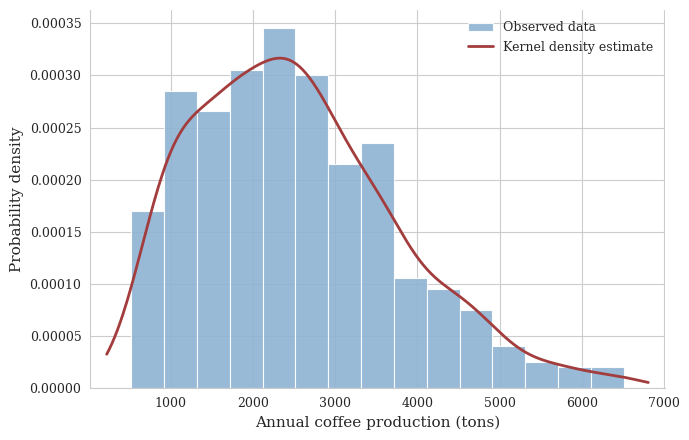

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from pathlib import Path

# Retrieve production data
if 'df' in globals() and 'Production_tons' in df.columns:
    prod = df['Production_tons'].dropna().to_numpy(dtype=float)
elif 'y' in globals() and np.asarray(y).size > 1:
    prod = np.asarray(y, dtype=float).ravel()
    prod = prod[np.isfinite(prod)]
else:
    raise RuntimeError(
        "Production data not found. Run the data preparation cell first."
    )

# Validate data
prod = prod[np.isfinite(prod)]

if prod.size < 2:
    raise ValueError("At least two valid observations are required.")

print(f"Sample size: {prod.size}")
print(f"Mean: {prod.mean():.2f} tons")
print(f"SD: {prod.std(ddof=1):.2f} tons")

# Output directory
fig_dir = Path(OUT_DIR) / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# Publication-style figure
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(7, 4.5))

# Histogram
ax.hist(
    prod,
    bins="auto",
    density=True,
    color="#8DB3D3",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.9,
    label="Observed data"
)

# KDE, if estimation is numerically appropriate
if prod.size >= 3 and np.ptp(prod) > 0:
    try:
        kde = gaussian_kde(prod)
        pad = 0.05 * np.ptp(prod)
        x_grid = np.linspace(
            max(0, prod.min() - pad),
            prod.max() + pad,
            400
        )
        ax.plot(
            x_grid,
            kde(x_grid),
            color="#A33D3D",
            linewidth=2,
            label="Kernel density estimate"
        )
    except (ValueError, np.linalg.LinAlgError):
        print("KDE could not be estimated reliably; histogram retained.")

ax.set_xlabel("Annual coffee production (tons)")
ax.set_ylabel("Probability density")

# Clean axes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", length=3, width=0.8)
ax.legend(frameon=False)
ax.margins(x=0.03)

fig.tight_layout()

# Save high-quality outputs
fig.savefig(
    fig_dir / "Fig3_Production_Distribution.pdf",
    bbox_inches="tight"
)
fig.savefig(
    fig_dir / "Fig3_Production_Distribution.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


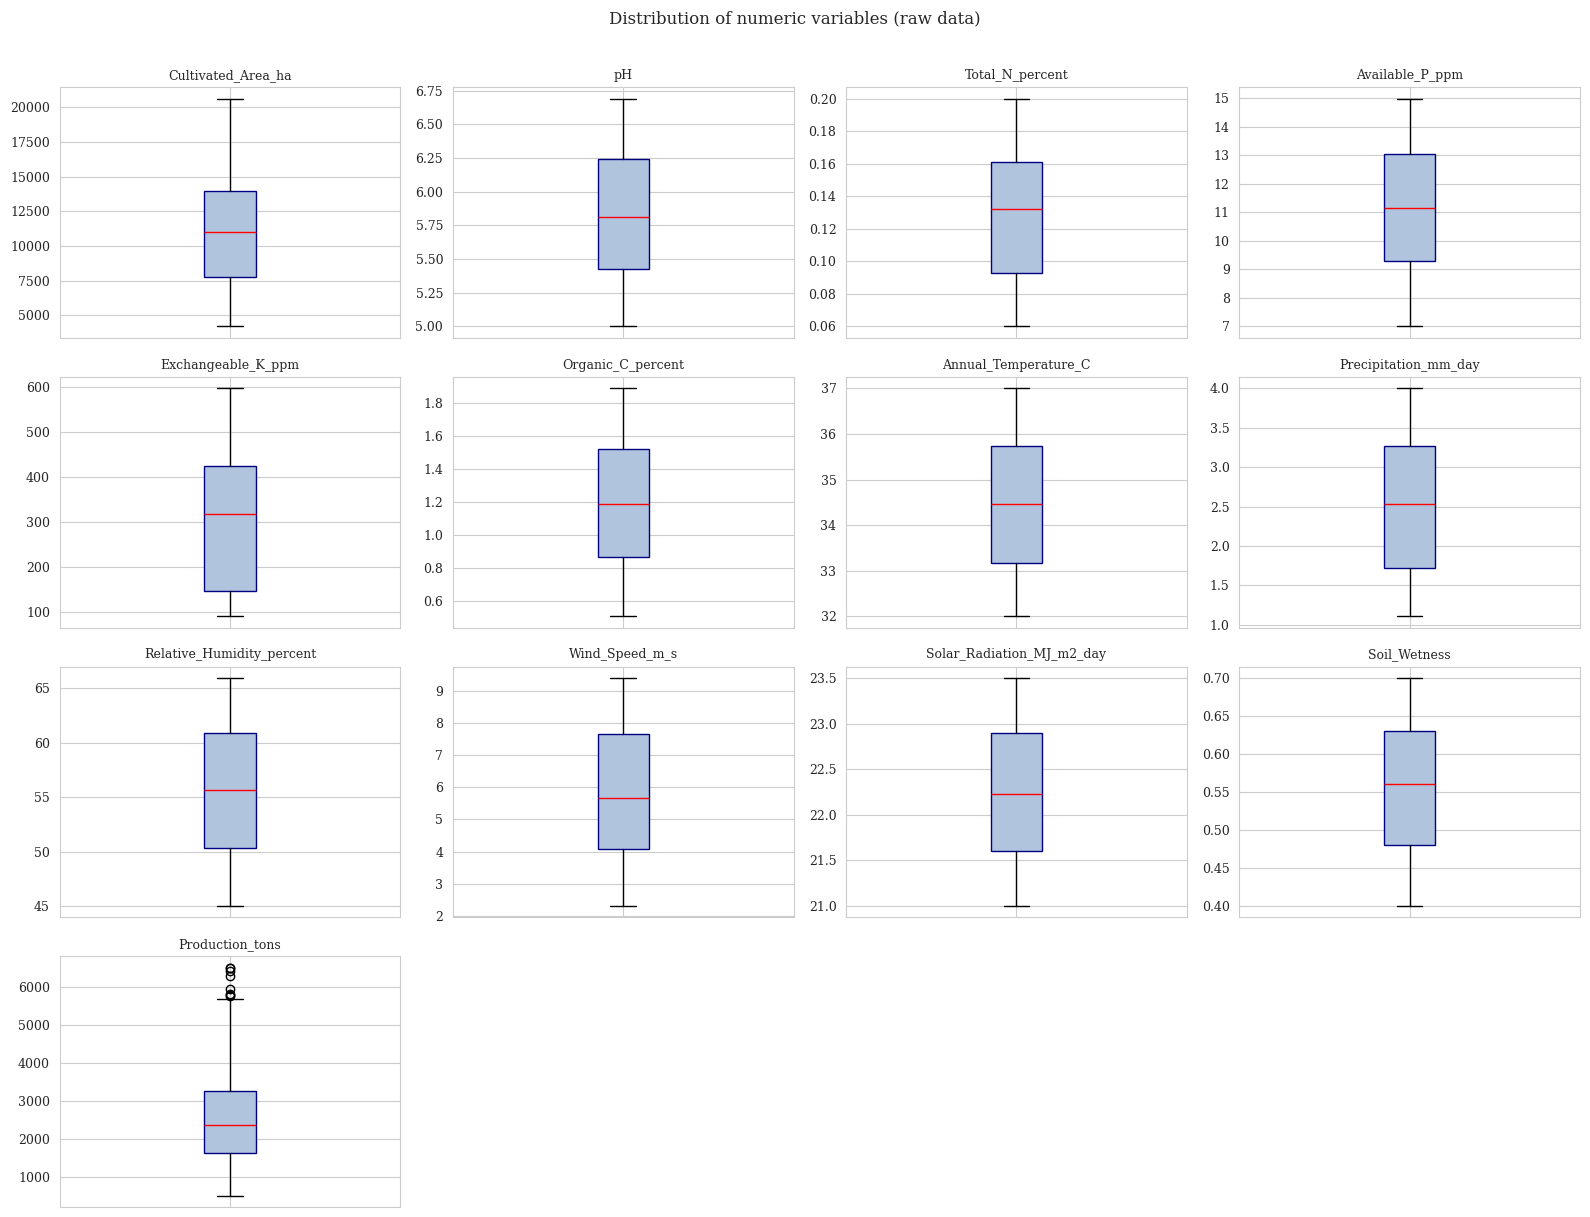

[SAVED] Fig4_Numeric_Boxplots


In [ ]:
# ==============================================================================
# FIG. 4 — Boxplots of key numeric variables
# ==============================================================================
box_cols = [
    'Cultivated_Area_ha', 'pH', 'Total_N_percent', 'Available_P_ppm',
    'Exchangeable_K_ppm', 'Organic_C_percent', 'Annual_Temperature_C',
    'Precipitation_mm_day', 'Relative_Humidity_percent',
    'Wind_Speed_m_s', 'Solar_Radiation_MJ_m2_day', 'Soil_Wetness',
    'Production_tons'
]
box_cols = [c for c in box_cols if c in df.columns]

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(box_cols):
    axes[i].boxplot(df[col].dropna(), vert=True, patch_artist=True,
                    boxprops=dict(facecolor='lightsteelblue',
                                  color='navy'),
                    medianprops=dict(color='red'))
    axes[i].set_title(col, fontsize=9)
    axes[i].tick_params(axis='x', labelbottom=False)

for j in range(len(box_cols), len(axes)):
    axes[j].axis('off')

plt.suptitle("Distribution of numeric variables (raw data)", y=1.01)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/Fig4_Numeric_Boxplots.png",
            bbox_inches='tight')
plt.savefig(f"{OUT_DIR}/figures/Fig4_Numeric_Boxplots.pdf",
            bbox_inches='tight')
plt.show()
print("[SAVED] Fig4_Numeric_Boxplots")

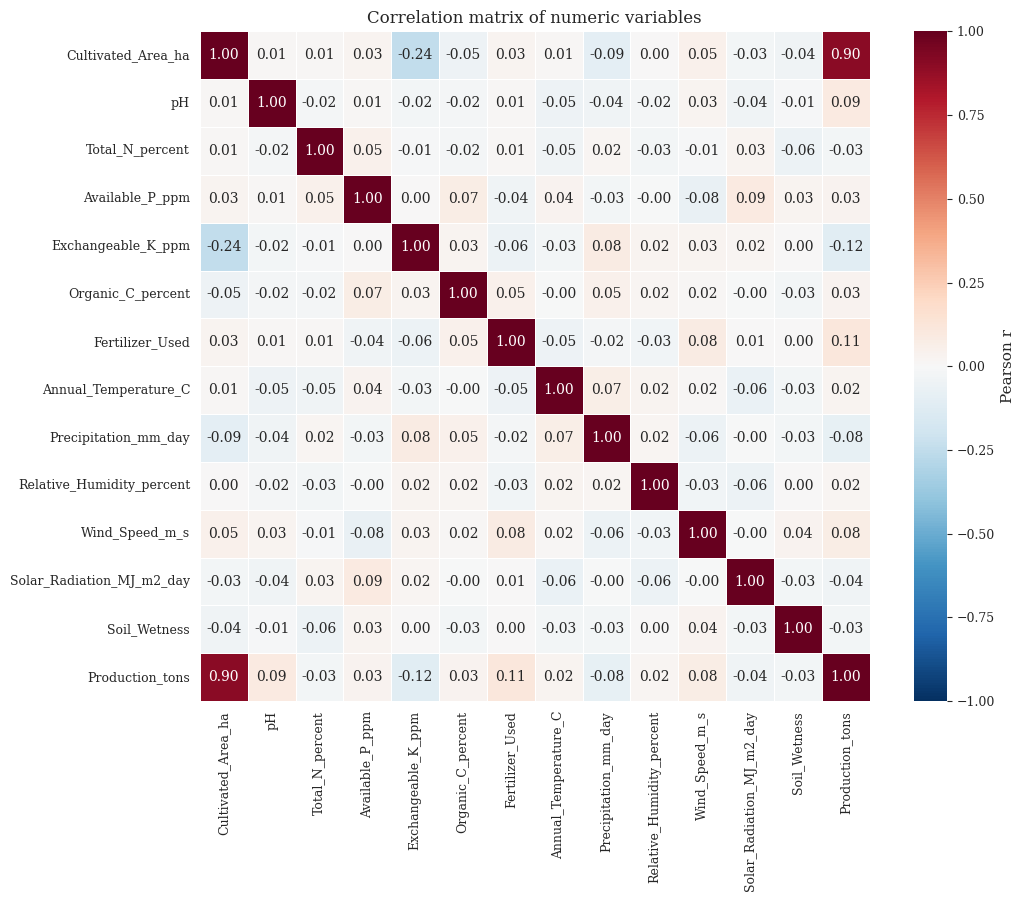

[SAVED] Fig5_Correlation_Heatmap

Top 10 absolute correlations:
Production_tons       Cultivated_Area_ha      0.898506
Cultivated_Area_ha    Production_tons         0.898506
                      Exchangeable_K_ppm      0.242228
Exchangeable_K_ppm    Cultivated_Area_ha      0.242228
Production_tons       Exchangeable_K_ppm      0.116278
Exchangeable_K_ppm    Production_tons         0.116278
Production_tons       Fertilizer_Used         0.111030
Fertilizer_Used       Production_tons         0.111030
Precipitation_mm_day  Cultivated_Area_ha      0.094719
Cultivated_Area_ha    Precipitation_mm_day    0.094719
dtype: float64


In [ ]:
# ==============================================================================
# FIG. 5 — Correlation heatmap of numeric variables
# ==============================================================================
num_cols = [c for c in df.select_dtypes(include=np.number).columns
            if c != 'Year']

corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='RdBu_r',
            center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5,
            cbar_kws={'label': 'Pearson r'}, ax=ax)
ax.set_title("Correlation matrix of numeric variables")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/Fig5_Correlation_Heatmap.png",
            bbox_inches='tight')
plt.savefig(f"{OUT_DIR}/figures/Fig5_Correlation_Heatmap.pdf",
            bbox_inches='tight')
plt.show()
print("[SAVED] Fig5_Correlation_Heatmap")

# Print the strongest correlations for the manuscript
corr_pairs = corr.unstack().sort_values(kind="quicksort", ascending=False)
corr_pairs = corr_pairs[corr_pairs < 0.999]
print("\nTop 10 absolute correlations:")
print(corr_pairs.abs().sort_values(ascending=False).head(10))

In [ ]:
# ==============================================================================
#  Train/test sizes
# ==============================================================================
unique_years = sorted(years.unique())
split_idx = len(unique_years) - 3
train_years = unique_years[:split_idx]
test_years  = unique_years[split_idx:]

train_mask = years.isin(train_years)
test_mask  = years.isin(test_years)

X_train, X_test = X[train_mask].copy(), X[test_mask].copy()
y_train, y_test = y[train_mask].copy(), y[test_mask].copy()

split_table = pd.DataFrame({
    'Set': ['Training', 'Test (chronological hold-out)'],
    'Years_EC': [f"{train_years[0]}–{train_years[-1]}", f"{test_years[0]}–{test_years[-1]}"],
    'N_observations': [len(X_train), len(X_test)],
    'Proportion': [round(len(X_train)/len(X), 3), round(len(X_test)/len(X), 3)]
})
print(split_table.to_string(index=False))
split_table.to_csv(f"{OUT_DIR}/tables/Table_S4_Train_Test_Sizes.csv", index=False)
print("[SAVED] Table_S4_Train_Test_Sizes.csv")
assert years[train_mask].max() < years[test_mask].min()
print("[OK] Strict chronological separation.")

                          Set  Years_EC  N_observations  Proportion
                     Training 2000–2012             389       0.778
Test (chronological hold-out) 2013–2015             111       0.222
[SAVED] Table_S4_Train_Test_Sizes.csv
[OK] Strict chronological separation.


In [ ]:
# ==============================================================================
# PART 5 — Preprocessing
# ==============================================================================
numerical_features = [
    'Cultivated_Area_ha', 'pH', 'Total_N_percent', 'Available_P_ppm',
    'Exchangeable_K_ppm', 'Organic_C_percent', 'Fertilizer_Used',
    'Annual_Temperature_C', 'Precipitation_mm_day',
    'Relative_Humidity_percent', 'Wind_Speed_m_s',
    'Solar_Radiation_MJ_m2_day', 'Soil_Wetness'
]
categorical_features = ['Soil_Type']   # only true categorical left

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numerical_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), categorical_features)
])

In [ ]:
# ==============================================================================
# PART 6 — Models
# ==============================================================================
models = {
    'Baseline_Mean': (
        Pipeline([('pre', preprocessor), ('reg', DummyRegressor(strategy='mean'))]), {}
    ),
    'Linear_Regression': (
        Pipeline([('pre', preprocessor), ('reg', LinearRegression())]), {}
    ),
    'Ridge': (
        Pipeline([('pre', preprocessor), ('reg', Ridge(random_state=RANDOM_SEED))]),
        {'reg__alpha': np.logspace(-3, 3, 25).tolist()}   # finer grid
    ),
    'ElasticNet': (
        Pipeline([('pre', preprocessor),
                  ('reg', ElasticNet(max_iter=10000, random_state=RANDOM_SEED))]),
        {'reg__alpha': [0.01, 0.1, 0.2, 1.0], 'reg__l1_ratio': [0.1, 0.5, 0.9]}
    ),
    'RandomForest': (
        Pipeline([('pre', preprocessor),
                  ('reg', RandomForestRegressor(random_state=RANDOM_SEED))]),
        {'reg__n_estimators': [100, 200], 'reg__max_depth': [5, 10, None],
         'reg__min_samples_leaf': [2, 4]}
    ),
    'GradientBoosting': (
        Pipeline([('pre', preprocessor),
                  ('reg', GradientBoostingRegressor(random_state=RANDOM_SEED))]),
        {'reg__n_estimators': [100, 200], 'reg__learning_rate': [0.05, 0.1],
         'reg__max_depth': [3, 5]}
    ),
    'XGBoost': (
        Pipeline([('pre', preprocessor),
                  ('reg', XGBRegressor(random_state=RANDOM_SEED, verbosity=0))]),
        {'reg__n_estimators': [100, 200], 'reg__learning_rate': [0.05, 0.1],
         'reg__max_depth': [3, 5], 'reg__subsample': [0.8, 1.0]}
    ),
    'SVR': (
        Pipeline([('pre', preprocessor), ('reg', SVR())]),
        {'reg__C': [1, 10, 100], 'reg__epsilon': [0.1, 0.2],
         'reg__kernel': ['linear', 'rbf']}
    )
}

In [ ]:
# ==============================================================================
# PART 7 — TimeSeries CV + Tuning + Fold-wise metrics
# ==============================================================================
tscv = TimeSeriesSplit(n_splits=5)
cv_results = {}
best_models = {}
best_params = {}
fold_metrics = []

for name, (pipe, param_grid) in models.items():
    print(f"\n>>> Tuning {name}")
    if param_grid:
        gs = GridSearchCV(pipe, param_grid, cv=tscv, scoring='r2',
                          n_jobs=-1, refit=True, return_train_score=False)
        gs.fit(X_train, y_train)
        best_models[name] = gs.best_estimator_
        best_params[name] = gs.best_params_
        cv_mean = gs.best_score_
        cv_std  = gs.cv_results_['std_test_score'][gs.best_index_]
        best_idx = gs.best_index_
        for fold_i in range(5):
            key = f'split{fold_i}_test_score'
            if key in gs.cv_results_:
                fold_metrics.append({'Model': name, 'Fold': fold_i+1,
                                     'R2': gs.cv_results_[key][best_idx]})
    else:
        scores = cross_val_score(pipe, X_train, y_train, cv=tscv, scoring='r2')
        pipe.fit(X_train, y_train)
        best_models[name] = pipe
        best_params[name] = {}
        cv_mean, cv_std = scores.mean(), scores.std()
        for fold_i, sc in enumerate(scores):
            fold_metrics.append({'Model': name, 'Fold': fold_i+1, 'R2': sc})

    cv_results[name] = {'CV_R2_Mean': cv_mean, 'CV_R2_Std': cv_std}
    print(f"    CV R² = {cv_mean:.4f} ± {cv_std:.4f}")
    if best_params[name]:
        print(f"    Best params: {best_params[name]}")

cv_df = pd.DataFrame(cv_results).T.sort_values('CV_R2_Mean', ascending=False)
print("\n=== Table 3: CV Results ===")
print(cv_df.round(4))
cv_df.to_csv(f"{OUT_DIR}/tables/Table3_CV_Results.csv")
cv_df.to_excel(f"{OUT_DIR}/tables/Table3_CV_Results.xlsx")
pd.DataFrame([{'Model': k, 'Params': str(v)} for k, v in best_params.items()])\
  .to_csv(f"{OUT_DIR}/tables/Table3b_Best_Parameters.csv", index=False)

fold_df = pd.DataFrame(fold_metrics)
fold_df.to_csv(f"{OUT_DIR}/tables/Table3c_Foldwise_CV_R2.csv", index=False)
print("[SAVED] Table3 + Table3b + Table3c")


>>> Tuning Baseline_Mean
    CV R² = -0.0574 ± 0.1065

>>> Tuning Linear_Regression
    CV R² = 0.8084 ± 0.0173

>>> Tuning Ridge
    CV R² = 0.8203 ± 0.0088
    Best params: {'reg__alpha': 10.0}

>>> Tuning ElasticNet
    CV R² = 0.8200 ± 0.0097
    Best params: {'reg__alpha': 0.1, 'reg__l1_ratio': 0.1}

>>> Tuning RandomForest
    CV R² = 0.7932 ± 0.0151
    Best params: {'reg__max_depth': None, 'reg__min_samples_leaf': 4, 'reg__n_estimators': 100}

>>> Tuning GradientBoosting
    CV R² = 0.7954 ± 0.0328
    Best params: {'reg__learning_rate': 0.05, 'reg__max_depth': 3, 'reg__n_estimators': 100}

>>> Tuning XGBoost
    CV R² = 0.8132 ± 0.0192
    Best params: {'reg__learning_rate': 0.1, 'reg__max_depth': 3, 'reg__n_estimators': 100, 'reg__subsample': 0.8}

>>> Tuning SVR
    CV R² = 0.8241 ± 0.0136
    Best params: {'reg__C': 100, 'reg__epsilon': 0.2, 'reg__kernel': 'linear'}

=== Table 3: CV Results ===
                   CV_R2_Mean  CV_R2_Std
SVR                    0.8241     0.01

In [ ]:
# ==============================================================================
# CELL 12 — Model Selection
# ==============================================================================
print("\n" + "=" * 80)
print("HONEST MODEL SELECTION")
print("=" * 80)

param_count = {
    'Baseline_Mean': 0, 'Linear_Regression': 0,
    'Ridge': 1, 'ElasticNet': 2, 'SVR': 3,
    'RandomForest': 4, 'GradientBoosting': 5, 'XGBoost': 6
}

cv_summaries = pd.DataFrame(cv_results).T
best_score = cv_summaries['CV_R2_Mean'].max()
best_se    = cv_summaries.loc[cv_summaries['CV_R2_Mean'].idxmax(),
                              'CV_R2_Std'] / np.sqrt(5)
threshold  = best_score - best_se

within_1se = cv_summaries[cv_summaries['CV_R2_Mean'] >= threshold].copy()
within_1se['Parsimony'] = within_1se.index.map(param_count)
within_1se = within_1se.sort_values(['Parsimony', 'CV_R2_Mean'],
                                     ascending=[True, False])

print(f"Best CV R² = {best_score:.4f}")
print(f"1-SE threshold = {threshold:.4f}")
print("Models within 1-SE (ordered by parsimony then score):")
print(within_1se[['CV_R2_Mean', 'CV_R2_Std', 'Parsimony']].round(4))

FINAL_MODEL_NAME = within_1se.index[0]
print(f"\n[SELECTED BY HONEST 1-SE + PARSIMONY] {FINAL_MODEL_NAME}")

final_model = best_models[FINAL_MODEL_NAME]

RIDGE_ALPHA = best_params.get('Ridge', {}).get('reg__alpha', 1.0)
print(f"[INFO] Tuned Ridge alpha locked to {RIDGE_ALPHA}")


HONEST MODEL SELECTION
Best CV R² = 0.8241
1-SE threshold = 0.8180
Models within 1-SE (ordered by parsimony then score):
            CV_R2_Mean  CV_R2_Std  Parsimony
Ridge           0.8203     0.0088          1
ElasticNet      0.8200     0.0097          2
SVR             0.8241     0.0136          3

[SELECTED BY HONEST 1-SE + PARSIMONY] Ridge
[INFO] Tuned Ridge alpha locked to 10.0


In [ ]:
# ==============================================================================
# PART 9 — Locked Test Evaluation
# ==============================================================================
test_results = {}
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    test_results[name] = {
        'R2':   r2_score(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'MAE':  mean_absolute_error(y_test, y_pred),
        'MAPE': mean_absolute_percentage_error(y_test, y_pred) * 100,
        'NRMSE': np.sqrt(mean_squared_error(y_test, y_pred)) / y_test.mean() * 100
    }

test_df = pd.DataFrame(test_results).T
test_df = test_df.join(pd.DataFrame(cv_results).T[['CV_R2_Mean']])
test_df = test_df.sort_values('R2', ascending=False)
print("\n=== Table 4: Test Performance ===")
print(test_df.round(4))
test_df.to_csv(f"{OUT_DIR}/tables/Table4_Test_Results.csv")
test_df.to_excel(f"{OUT_DIR}/tables/Table4_Test_Results.xlsx")

print(f"\n>>> FINAL MODEL ({FINAL_MODEL_NAME}):")
print(f"    R²   = {test_results[FINAL_MODEL_NAME]['R2']:.4f}")
print(f"    RMSE = {test_results[FINAL_MODEL_NAME]['RMSE']:.2f} tons")
print(f"    MAE  = {test_results[FINAL_MODEL_NAME]['MAE']:.2f} tons")


=== Table 4: Test Performance ===
                       R2       RMSE       MAE     MAPE    NRMSE  CV_R2_Mean
Ridge              0.8409   465.7568  360.1691  14.7206  17.4254      0.8203
ElasticNet         0.8408   465.8997  354.7697  14.5740  17.4308      0.8200
Linear_Regression  0.8370   471.5085  366.9164  14.9365  17.6406      0.8084
SVR                0.8320   478.5976  364.4623  14.7589  17.9059      0.8241
GradientBoosting   0.8299   481.5572  360.6622  13.9503  18.0166      0.7954
RandomForest       0.8267   486.1080  373.7600  14.6483  18.1868      0.7932
XGBoost            0.8126   505.5510  386.6350  14.7370  18.9143      0.8132
Baseline_Mean     -0.0299  1185.0405  949.8273  43.4178  44.3361     -0.0574

>>> FINAL MODEL (Ridge):
    R²   = 0.8409
    RMSE = 465.76 tons
    MAE  = 360.17 tons


In [ ]:
# ==============================================================================
# CRITICAL #1 — Rolling-origin
# ==============================================================================
print("\n" + "=" * 80)
print("ROLLING-ORIGIN VALIDATION")
print("=" * 80)

rolling_results = []
unique_yrs = sorted(years.unique())
min_train_years = 8
for i in range(min_train_years, len(unique_yrs)-1):
    tr_yrs = unique_yrs[:i]
    te_yr  = unique_yrs[i]
    tr_mask = years.isin(tr_yrs)
    te_mask = years == te_yr
    if te_mask.sum() < 5:
        continue
    Xtr, ytr = X[tr_mask], y[tr_mask]
    Xte, yte = X[te_mask], y[te_mask]

    pipe_roll = Pipeline([
        ('pre', preprocessor),
        ('reg', Ridge(alpha=RIDGE_ALPHA, random_state=RANDOM_SEED))
    ])
    pipe_roll.fit(Xtr, ytr)
    yp = pipe_roll.predict(Xte)
    rolling_results.append({
        'Train_end_year': tr_yrs[-1], 'Test_year': te_yr,
        'N_train': len(Xtr), 'N_test': len(Xte),
        'R2': r2_score(yte, yp),
        'RMSE': np.sqrt(mean_squared_error(yte, yp)),
        'MAE': mean_absolute_error(yte, yp)
    })

roll_df = pd.DataFrame(rolling_results)
print(roll_df.round(4).to_string(index=False))
roll_df.to_csv(f"{OUT_DIR}/tables/Table6_Rolling_Origin.csv", index=False)
print(f"[SAVED] Table6_Rolling_Origin.csv")
print(f"Mean rolling R² = {roll_df['R2'].mean():.4f} ± {roll_df['R2'].std():.4f}")


ROLLING-ORIGIN VALIDATION
 Train_end_year  Test_year  N_train  N_test     R2     RMSE      MAE
           2007       2008      256      21 0.7531 612.8634 390.2413
           2008       2009      277      18 0.8714 492.4828 345.0018
           2009       2010      295      36 0.7287 522.6654 361.5920
           2010       2011      331      28 0.8587 432.6996 344.5535
           2011       2012      359      30 0.7986 500.5492 372.7202
           2012       2013      389      31 0.8335 496.7605 391.1705
           2013       2014      420      32 0.8657 423.3444 374.1528
[SAVED] Table6_Rolling_Origin.csv
Mean rolling R² = 0.8157 ± 0.0571


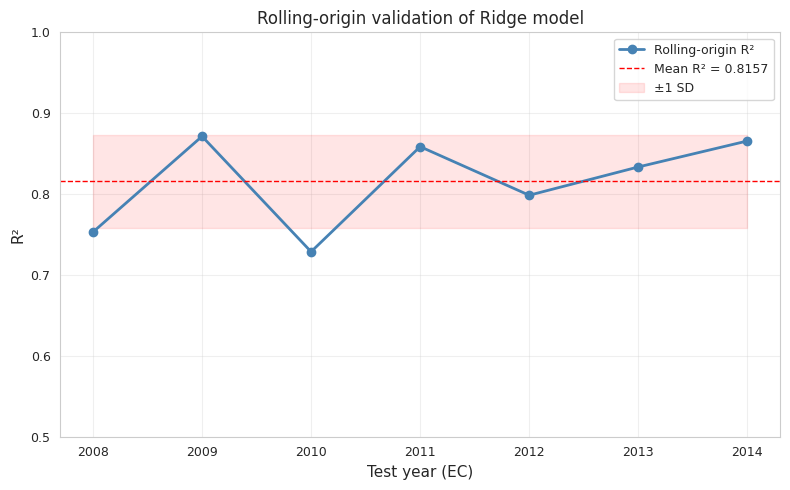

[SAVED] Fig9_Rolling_Origin_R2


In [ ]:
# ==============================================================================
# FIG. 9 — Rolling-origin R² across test years
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(roll_df['Test_year'], roll_df['R2'],
        marker='o', linewidth=2, color='steelblue',
        label='Rolling-origin R²')
ax.axhline(roll_df['R2'].mean(), color='red', linestyle='--',
           linewidth=1,
           label=f"Mean R² = {roll_df['R2'].mean():.4f}")
ax.fill_between(roll_df['Test_year'],
                roll_df['R2'].mean() - roll_df['R2'].std(),
                roll_df['R2'].mean() + roll_df['R2'].std(),
                color='red', alpha=0.10,
                label='±1 SD')

ax.set_xlabel("Test year (EC)")
ax.set_ylabel("R²")
ax.set_ylim(0.5, 1.0)
ax.set_title("Rolling-origin validation of Ridge model")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/Fig9_Rolling_Origin_R2.png",
            bbox_inches='tight')
plt.savefig(f"{OUT_DIR}/figures/Fig9_Rolling_Origin_R2.pdf",
            bbox_inches='tight')
plt.show()
print("[SAVED] Fig9_Rolling_Origin_R2")

In [ ]:
# ==============================================================================
# Random vs Chronological comparison
# ==============================================================================
print("\n" + "=" * 80)
print("RANDOM vs CHRONOLOGICAL COMPARISON")
print("=" * 80)

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED)

pipe_rand = Pipeline([
    ('pre', preprocessor),
    ('reg', Ridge(alpha=RIDGE_ALPHA, random_state=RANDOM_SEED))
])
pipe_rand.fit(X_tr_r, y_tr_r)
yp_rand = pipe_rand.predict(X_te_r)

rand_r2 = r2_score(y_te_r, yp_rand)
chrono_r2 = test_results.get('Ridge', test_results[FINAL_MODEL_NAME])['R2']

print(f"  Random split   R² = {rand_r2:.4f}")
print(f"  Chronological  R² = {chrono_r2:.4f}")

comp = pd.DataFrame({
    'Split': ['Random 80:20', 'Chronological hold-out'],
    'R2': [rand_r2, chrono_r2]
})
comp.to_csv(f"{OUT_DIR}/tables/Table_S5_Random_vs_Chronological.csv", index=False)
print("[SAVED] Table_S5_Random_vs_Chronological.csv")

print("\n[LODO] Skipped — District was dropped after audit.")


RANDOM vs CHRONOLOGICAL COMPARISON
  Random split   R² = 0.8520
  Chronological  R² = 0.8409
[SAVED] Table_S5_Random_vs_Chronological.csv

[LODO] Skipped — District was dropped after audit.


In [ ]:
# ==============================================================================
# PROPER CALIBRATION
# ==============================================================================
print("\n" + "=" * 80)
print("MODEL CALIBRATION")
print("=" * 80)

y_pred_final = final_model.predict(X_test)
slope, intercept, r_val, p_val, se = linregress(y_pred_final, y_test)

print(f"Calibration slope     = {slope:.3f} ± {se:.3f}   (ideal = 1.00)")
print(f"Calibration intercept = {intercept:.2f}          (ideal = 0.00)")
print(f"Pearson r             = {r_val:.4f},  p = {p_val:.2e}")

if abs(slope - 1) < 0.1 and abs(intercept) < 50:
    print("  → Calibration is acceptable (near 1:1 with small intercept).")
elif slope < 0.9:
    print("  → Slope < 1: model under-predicts extremes.")
elif slope > 1.1:
    print("  → Slope > 1: model over-predicts extremes.")
else:
    print("  → Mild deviation from ideal calibration.")

calib = pd.DataFrame({
    'Metric': ['Slope', 'Intercept', 'Pearson_r', 'p_value'],
    'Value': [slope, intercept, r_val, p_val]
})
calib.to_csv(f"{OUT_DIR}/tables/Table_S6_Calibration.csv", index=False)
print("[SAVED] Table_S6_Calibration.csv")


MODEL CALIBRATION
Calibration slope     = 0.988 ± 0.041   (ideal = 1.00)
Calibration intercept = 55.49          (ideal = 0.00)
Pearson r             = 0.9173,  p = 2.15e-45
  → Mild deviation from ideal calibration.
[SAVED] Table_S6_Calibration.csv


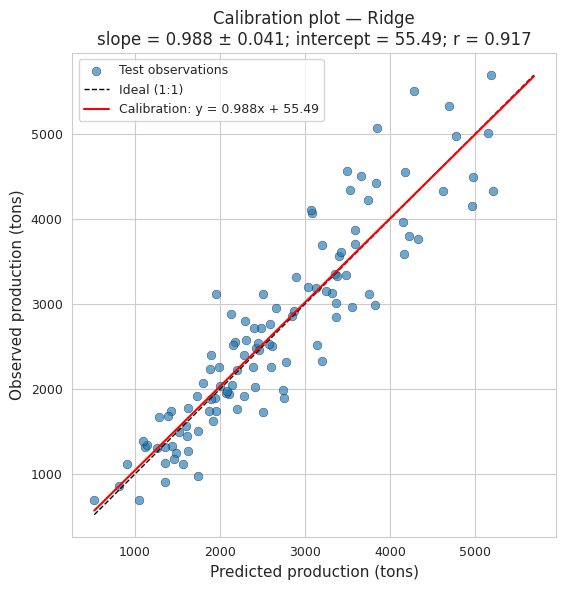

[SAVED] Fig8_Calibration


In [ ]:
# ==============================================================================
# FIG. 8 — Calibration plot (observed vs predicted with 1:1 line)
# ==============================================================================
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(y_pred_final, y_test, alpha=0.65,
           edgecolor='k', linewidth=0.3, s=40, label='Test observations')

lims = [min(y_pred_final.min(), y_test.min()),
        max(y_pred_final.max(), y_test.max())]

# Ideal 1:1 line
ax.plot(lims, lims, 'k--', linewidth=1, label='Ideal (1:1)')

# Fitted calibration line
ax.plot(lims, slope * np.array(lims) + intercept,
        color='red', linewidth=1.5,
        label=f'Calibration: y = {slope:.3f}x + {intercept:.2f}')

ax.set_xlabel("Predicted production (tons)")
ax.set_ylabel("Observed production (tons)")
ax.set_title(f"Calibration plot — {FINAL_MODEL_NAME}\n"
             f"slope = {slope:.3f} ± {se:.3f}; "
             f"intercept = {intercept:.2f}; r = {r_val:.3f}")
ax.legend(loc='upper left')
ax.set_aspect('equal', 'box')
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/Fig8_Calibration.png", bbox_inches='tight')
plt.savefig(f"{OUT_DIR}/figures/Fig8_Calibration.pdf", bbox_inches='tight')
plt.show()
print("[SAVED] Fig8_Calibration")

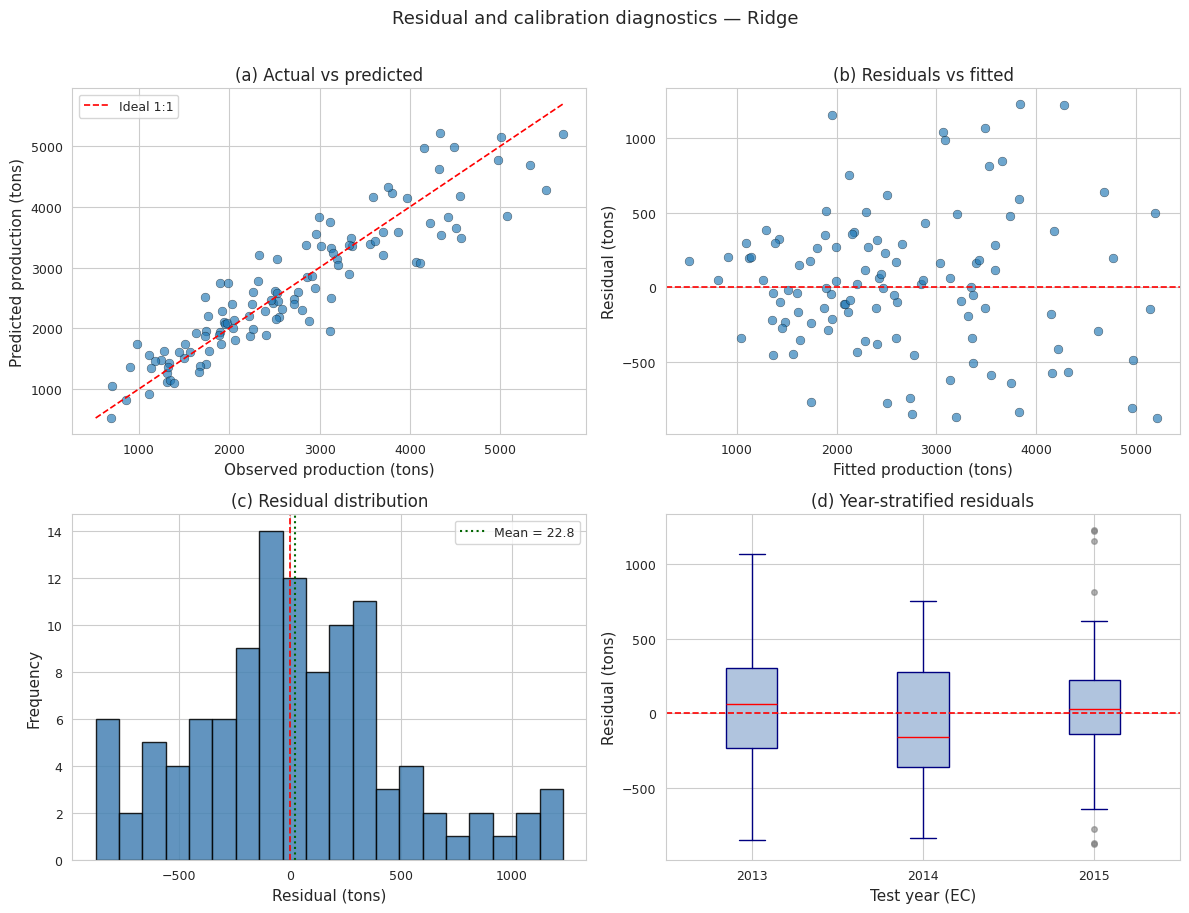


[RESIDUAL SUMMARY — test set]
  N          = 111
  Mean bias  = +22.80 tons
  Std        = 467.31 tons
  Min        = -877.08 tons
  Max        = +1229.97 tons
  Skewness   = 0.348
  Kurtosis   = 0.134

[SAVED] Fig7_Residuals_Full (a/b/c/d)


In [ ]:
# ==============================================================================
# FIG. 7 — Residual and calibration diagnostics (final Ridge model)
# (a) actual vs predicted | (b) residuals vs fitted
# (c) residual distribution | (d) year-stratified residuals
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt

# --- Predictions and residuals on the chronological test set ---
y_pred_final   = final_model.predict(X_test)
residuals      = y_test.values - y_pred_final
test_years_arr = years[test_mask].values

# --- Shared aesthetics ---
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# =====================================================================
# (a) Actual vs Predicted
# =====================================================================
ax = axes[0, 0]
ax.scatter(y_test, y_pred_final, alpha=0.65, edgecolor='k', lw=0.3, s=40)
lims = [min(y_test.min(), y_pred_final.min()),
        max(y_test.max(), y_pred_final.max())]
ax.plot(lims, lims, 'r--', linewidth=1.2, label='Ideal 1:1')
ax.set_xlabel("Observed production (tons)")
ax.set_ylabel("Predicted production (tons)")
ax.set_title("(a) Actual vs predicted")
ax.legend(loc='upper left')

# =====================================================================
# (b) Residuals vs Fitted
# =====================================================================
ax = axes[0, 1]
ax.scatter(y_pred_final, residuals, alpha=0.65, edgecolor='k', lw=0.3, s=40)
ax.axhline(0, color='red', linestyle='--', linewidth=1.2)
ax.set_xlabel("Fitted production (tons)")
ax.set_ylabel("Residual (tons)")
ax.set_title("(b) Residuals vs fitted")

# =====================================================================
# (c) Residual distribution
# =====================================================================
ax = axes[1, 0]
ax.hist(residuals, bins=20, edgecolor='k', color='steelblue', alpha=0.85)
ax.axvline(0, color='red', linestyle='--', linewidth=1.2)
ax.axvline(residuals.mean(), color='darkgreen', linestyle=':',
           linewidth=1.5,
           label=f"Mean = {residuals.mean():.1f}")
ax.set_xlabel("Residual (tons)")
ax.set_ylabel("Frequency")
ax.set_title("(c) Residual distribution")
ax.legend()

# =====================================================================
# (d) Year-stratified residuals
# =====================================================================
ax = axes[1, 1]
unique_test_years = sorted(np.unique(test_years_arr))

# Boxplot residuals per test year
year_data = [residuals[test_years_arr == y] for y in unique_test_years]
ax.boxplot(year_data, labels=unique_test_years,
           patch_artist=True,
           boxprops=dict(facecolor='lightsteelblue', color='navy'),
           medianprops=dict(color='red'),
           whiskerprops=dict(color='navy'),
           capprops=dict(color='navy'),
           flierprops=dict(marker='o', markersize=4,
                           markerfacecolor='gray',
                           markeredgecolor='gray', alpha=0.6))
ax.axhline(0, color='red', linestyle='--', linewidth=1.2)
ax.set_xlabel("Test year (EC)")
ax.set_ylabel("Residual (tons)")
ax.set_title("(d) Year-stratified residuals")

# =====================================================================
# Save
# =====================================================================
plt.suptitle(f"Residual and calibration diagnostics — {FINAL_MODEL_NAME}",
             y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/Fig7_Residuals_Full.png",
            bbox_inches='tight')
plt.savefig(f"{OUT_DIR}/figures/Fig7_Residuals_Full.pdf",
            bbox_inches='tight')
plt.show()

# --- Print numeric diagnostics for the manuscript ---
print("\n[RESIDUAL SUMMARY — test set]")
print(f"  N          = {len(residuals)}")
print(f"  Mean bias  = {residuals.mean():+.2f} tons")
print(f"  Std        = {residuals.std(ddof=1):.2f} tons")
print(f"  Min        = {residuals.min():+.2f} tons")
print(f"  Max        = {residuals.max():+.2f} tons")
print(f"  Skewness   = {float(((residuals - residuals.mean())**3).mean() / residuals.std()**3):.3f}")
print(f"  Kurtosis   = {float(((residuals - residuals.mean())**4).mean() / residuals.std()**4 - 3):.3f}")
print(f"\n[SAVED] Fig7_Residuals_Full (a/b/c/d)")


X_test shape: (111, 14)
                  Feature  Importance_Mean  Importance_Std
       Cultivated_Area_ha         1.180515        0.112767
                Soil_Type         0.072618        0.018213
          Fertilizer_Used         0.007901        0.004950
                       pH         0.006587        0.006184
       Exchangeable_K_ppm         0.002232        0.006203
          Available_P_ppm         0.000743        0.000910
Relative_Humidity_percent         0.000474        0.000339
     Precipitation_mm_day         0.000243        0.000612
     Annual_Temperature_C         0.000160        0.001730
        Organic_C_percent        -0.000064        0.005863
          Total_N_percent        -0.000902        0.002331
Solar_Radiation_MJ_m2_day        -0.001148        0.000600
             Soil_Wetness        -0.002113        0.001587
           Wind_Speed_m_s        -0.004955        0.002646


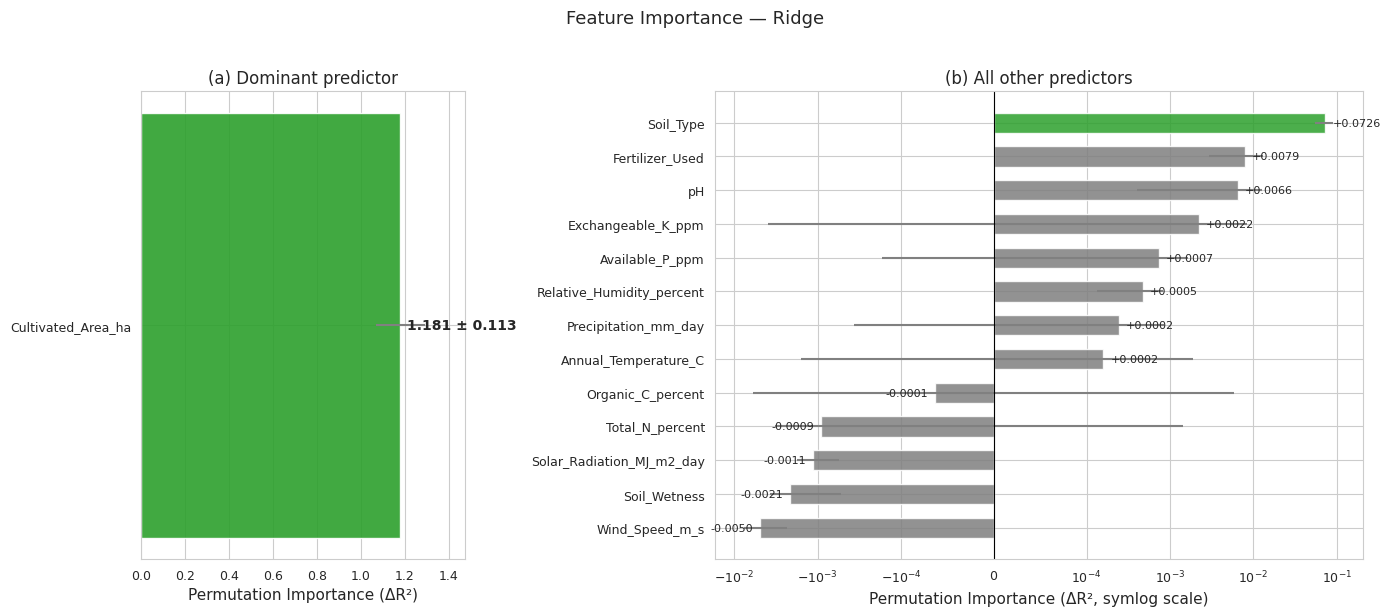

[SAVED] Fig6 + Table5


In [ ]:
# ==============================================================================
# PART 11 — Permutation Importance (two-panel plot with value labels)
# ==============================================================================
print(f"\nX_test shape: {X_test.shape}")

perm = permutation_importance(
    final_model, X_test, y_test,
    n_repeats=30, random_state=RANDOM_SEED, scoring='r2'
)

feat_names = list(X_test.columns)
assert len(feat_names) == len(perm.importances_mean), "Feature name length mismatch!"

imp_df = pd.DataFrame({
    'Feature': feat_names,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std':  perm.importances_std
}).sort_values('Importance_Mean', ascending=False)

# ---- Save tables ----
print(imp_df.to_string(index=False))
imp_df.to_csv(f"{OUT_DIR}/tables/Table5_Permutation_Importance.csv", index=False)
imp_df.to_excel(f"{OUT_DIR}/tables/Table5_Permutation_Importance.xlsx", index=False)

# ---- Two-panel figure so ALL features are visible ----
top_feat    = imp_df.iloc[0]              # Cultivated_Area_ha
other_feats = imp_df.iloc[1:].iloc[::-1]  # everything else, reversed for barh

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    gridspec_kw={'width_ratios': [1, 2]}
)

# ---------- Panel A: dominant feature ----------
ax = axes[0]
ax.barh([top_feat['Feature']], [top_feat['Importance_Mean']],
        xerr=[top_feat['Importance_Std']],
        color='#2ca02c', alpha=0.9, ecolor='gray', height=0.5)
ax.set_xlabel("Permutation Importance (ΔR²)")
ax.set_title("(a) Dominant predictor")
ax.annotate(
    f"{top_feat['Importance_Mean']:.3f} ± {top_feat['Importance_Std']:.3f}",
    xy=(top_feat['Importance_Mean'], 0),
    xytext=(5, 0), textcoords='offset points',
    va='center', fontsize=10, fontweight='bold'
)
ax.set_xlim(0, top_feat['Importance_Mean'] * 1.25)

# ---------- Panel B: all other features ----------
ax = axes[1]
colors = ['#2ca02c' if v > 0.05 else '#ff7f0e' if v > 0.01 else '#7f7f7f'
          for v in other_feats['Importance_Mean']]
bars = ax.barh(other_feats['Feature'], other_feats['Importance_Mean'],
               xerr=other_feats['Importance_Std'],
               color=colors, alpha=0.85, ecolor='gray', height=0.6)

# Symlog scale so negative importances also visible
ax.set_xscale('symlog', linthresh=1e-4)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel("Permutation Importance (ΔR², symlog scale)")
ax.set_title("(b) All other predictors")

# Annotate each bar with its numeric value
for bar, val, std in zip(bars,
                          other_feats['Importance_Mean'],
                          other_feats['Importance_Std']):
    x = bar.get_width()
    y = bar.get_y() + bar.get_height() / 2
    offset = 5 if x >= 0 else -5
    ha = 'left' if x >= 0 else 'right'
    ax.annotate(f"{val:+.4f}",
                xy=(x, y), xytext=(offset, 0),
                textcoords='offset points',
                va='center', ha=ha, fontsize=8)

plt.suptitle(f"Feature Importance — {FINAL_MODEL_NAME}", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/Fig6_Permutation_Importance.png", bbox_inches='tight')
plt.savefig(f"{OUT_DIR}/figures/Fig6_Permutation_Importance.pdf", bbox_inches='tight')
plt.show()
print("[SAVED] Fig6 + Table5")

In [ ]:
# ==============================================================================
# PART 12 — No-area model (uses locked RIDGE_ALPHA)
# ==============================================================================
FEATURES_no = [f for f in FEATURES if f != 'Cultivated_Area_ha']
num_no = [f for f in numerical_features if f != 'Cultivated_Area_ha']

pre_no = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), num_no),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore',
                                           sparse_output=False))]), categorical_features)
])

model_no = Pipeline([
    ('pre', pre_no),
    ('reg', Ridge(alpha=RIDGE_ALPHA, random_state=RANDOM_SEED))
])
model_no.fit(X_train[FEATURES_no], y_train)
yp_no = model_no.predict(X_test[FEATURES_no])

print(f"Ridge WITHOUT Cultivated_Area_ha:")
print(f"  Test R²   = {r2_score(y_test, yp_no):.4f}")
print(f"  R² drop   = {test_results.get('Ridge', test_results[FINAL_MODEL_NAME])['R2'] - r2_score(y_test, yp_no):.4f}")

Ridge WITHOUT Cultivated_Area_ha:
  Test R²   = 0.6192
  R² drop   = 0.2217
